# Latih & Validasi Model PASCA_OPERASI

**Pemilik:** Raymond · **Algoritma:** Logistic Regression multinomial (label 0 tidak sesuai / 1 cukup / 2 sangat sesuai)

Notebook ini menggantikan `latih_pasca_operasi.py` dan `validasi_pasca_operasi.py`. Kode training, fitur, hyperparameter, dan seed
sama untuk keempat kategori (`shared/training.py`); yang khusus kategori ada di `pasca_operasi/ai_models/`
(`profil.py`, `rubrik.py`, `bahaya.py`, `skenario.py`).

**Skema evaluasi**

| Tahap | Data | Tujuan |
|---|---|---|
| Validasi silang GroupKFold 5 lipatan | 80% profil (data latih) | skor latih vs validasi per lipatan, cek overfitting, kurva belajar |
| Test set (held-out) | 20% profil baru + 15% makanan baru | estimasi akhir yang jujur, dipakai **sekali** untuk model final |

Split dilakukan **per profil**: profil yang sama tidak pernah muncul di data latih dan validasi/test sekaligus.

**Cara menjalankan:** buka di VS Code / JupyterLab / Colab, lalu *Run All*. Hugging Face Space tetap menjalankan
`app.py` (API); notebook ini hanya untuk melatih model dan membuat laporan. Model hasil latih disimpan ke
`pasca_operasi/model/recommender_PASCA_OPERASI.joblib` dan dipakai API.

In [1]:
import os, sys

# Cari root repo (folder yang berisi model.py) agar notebook bisa dijalankan dari folder mana pun
ROOT = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(ROOT, 'model.py')):
    if os.path.dirname(ROOT) == ROOT:
        raise RuntimeError('Root repo (model.py) tidak ditemukan. Jalankan notebook dari dalam repo.')
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)
os.chdir(ROOT)
os.environ.setdefault('AI_ALLOW_SNAPSHOT_FALLBACK', '1')   # uji end-to-end memakai snapshot bila Supabase offline

KATEGORI = 'PASCA_OPERASI'
BUAT_DATA = False      # True = buat ulang dataset sintetis dari profil.py & rubrik.py kategori ini
JUMLAH_PROFIL = 700

import pandas as pd
from IPython.display import Markdown, display
from shared import PEMILIK, data_dir
from shared import grafik
from shared.pipeline import latih_kategori, validasi_kategori

pd.set_option('display.width', 160)
print(f'Model {KATEGORI} | pemilik {PEMILIK[KATEGORI]} | root {ROOT}')

Model PASCA_OPERASI | pemilik Raymond | root D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway


## 1. Dataset sintetis

,baris,profil,makanan unik,baris makanan baru
Latih,33583,560,6990,0
Test,8397,140,4717,1280


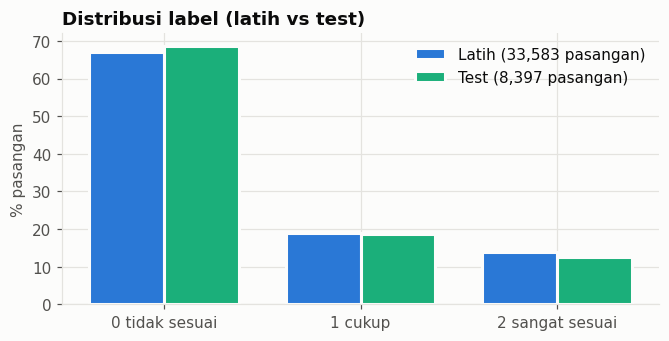

In [2]:
if BUAT_DATA:
    from shared.dataset import generate_category_dataset, load_food_catalog
    generate_category_dataset(load_food_catalog(os.path.join(ROOT, 'data', 'nutrition.csv')), KATEGORI, JUMLAH_PROFIL)

df_train = pd.read_csv(os.path.join(data_dir(KATEGORI), 'train_data.csv'))
df_test = pd.read_csv(os.path.join(data_dir(KATEGORI), 'test_data.csv'))
display(pd.DataFrame({
    'baris': [len(df_train), len(df_test)],
    'profil': [df_train['profile_id'].nunique(), df_test['profile_id'].nunique()],
    'makanan unik': [df_train['food_name'].nunique(), df_test['food_name'].nunique()],
    'baris makanan baru': [int(df_train['is_new_food'].sum()), int(df_test['is_new_food'].sum())],
}, index=['Latih', 'Test']))
grafik.distribusi_label(df_train, df_test)

## 2. Latih model

Validasi silang, model final, pembanding gradient boosting, dan kurva belajar (sekitar 1-2 menit).

In [3]:
h = latih_kategori(KATEGORI)

  NUTRISCALE AI — MODEL PASCA_OPERASI (pemilik: Raymond)
  Logistic Regression multinomial | skor = (P(cukup) + 2 * P(sangat sesuai)) / 2



[PASCA_OPERASI] Memuat Dataset:
  - Training samples : 33583 baris (560 profil)
  - Testing samples  : 8397 baris (140 profil baru, Held-Out)
  - Distribusi label : {0: 0.67, 1: 0.19, 2: 0.14}
  - Fitur input      : 99 fitur (model.FEATURE_COLS)


  GroupKFold (5 fold): kappa 0.9351 ± 0.0014 | macro-F1 latih 0.9036 vs validasi 0.8986 ± 0.0026 | NDCG@5 0.9873


  Test (profil baru): Acc 0.9332 | macro-F1 0.8972 | kappa 0.9320
  Macro precision 0.9036 | macro recall 0.8917
    Kelas 0: precision 0.9670 | recall 0.9721 | F1 0.9695 | n=5762
    Kelas 1: precision 0.8130 | recall 0.8343 | F1 0.8235 | n=1569
    Kelas 2: precision 0.9307 | recall 0.8687 | F1 0.8986 | n=1066
  Confusion matrix (baris=asli, kolom=prediksi): [[5601, 161, 0], [191, 1309, 69], [0, 140, 926]]
  NDCG@5  model 0.9899 | formula lama 0.7416 | acak 0.6149
  Subset makanan baru (1280 baris): macro-F1 0.8613 | kappa 0.9051
  Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.00% (di produksi dibuang dulu oleh safety filter)
  Pembanding gradient boosting: Acc 0.9614 | macro-F1 0.9385 | kappa 0.9608 | NDCG@5 0.9960
  Overfitting: macro-F1 latih 0.9035 | validasi CV 0.8986 | test 0.8972 -> tidak overfitting (gradient boosting: selisih +0.0504)
  Koefisien teratas (P2 vs P0): [('any_conflict', -9.6186), ('natrium_lewat_jauh', -7.8156), ('gula_lewat_jauh', -7.0608), (

## 3. Validasi silang GroupKFold (latih vs validasi)

Tiap lipatan melatih model di 4/5 profil latih dan menguji di 1/5 profil sisanya. Kolom `train_*` = skor pada data
yang dipakai melatih, `val_*` = skor pada profil yang belum pernah dilihat.

,train_accuracy,val_accuracy,train_macro_f1,val_macro_f1,selisih_f1,train_log_loss,val_log_loss,val_weighted_kappa,val_ndcg@5
fold,,,,,,,,,
1,0.9357,0.9321,0.9029,0.9013,0.0016,0.1399,0.1518,0.9366,0.9871
2,0.9357,0.9314,0.9032,0.8997,0.0035,0.1408,0.1485,0.9362,0.9880
3,0.9349,0.9335,0.9029,0.8975,0.0054,0.1417,0.1447,0.9346,0.9862
4,0.9355,0.9342,0.9036,0.9001,0.0035,0.1419,0.1450,0.9351,0.9897
5,0.9363,0.9309,0.9052,0.8946,0.0106,0.1412,0.1468,0.9331,0.9854


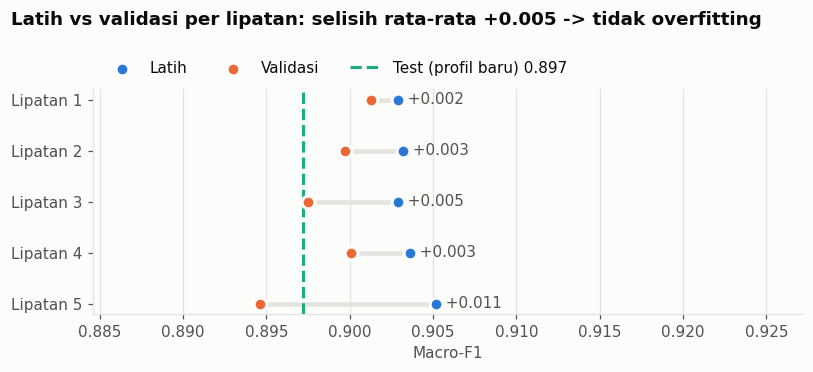

In [4]:
display(grafik.tabel_cv_per_fold(h))
grafik.latih_vs_validasi(h)

## 4. Cek overfitting

Overfitting = model menghafal data latih: skor latih jauh lebih tinggi daripada skor data baru.
Ukurannya adalah **selisih macro-F1 latih − validasi/test**:

| Selisih | Kesimpulan |
|---|---|
| ≤ 0,02 | tidak overfitting |
| ≤ 0,05 | overfitting ringan |
| > 0,05 | overfitting |

Bila skor latih **dan** validasi sama-sama rendah, masalahnya underfitting (model terlalu sederhana), bukan overfitting.
Gradient boosting ditampilkan sebagai pembanding model yang lebih kompleks.

accuracy  macro_f1  weighted_kappa  log_loss
Model               Data                                                                 
Logistic Regression Latih (model final)        0.9356    0.9035          0.9385    0.1416
                    Latih (rata-rata CV)       0.9356    0.9036          0.9386    0.1411
                    Validasi (rata-rata CV)    0.9324    0.8986          0.9351    0.1474
                    Test (profil baru)         0.9332    0.8972          0.9320    0.1436
Gradient boosting   Latih                      0.9929    0.9889          0.9931    0.0472
                    Test (profil baru)         0.9614    0.9385          0.9608    0.1038

Logistic Regression : selisih F1 latih-CV +0.0049, latih-test +0.0063 -> tidak overfitting
Gradient boosting   : selisih F1 latih-test +0.0504 -> overfitting


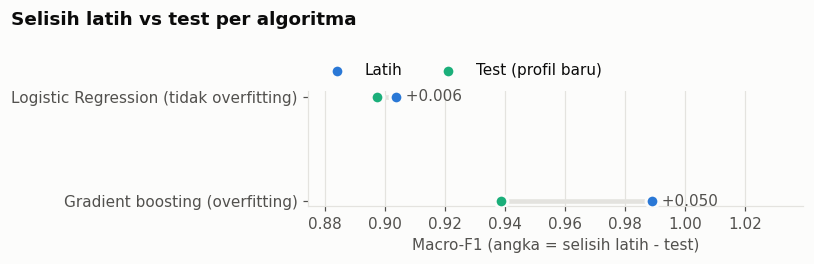

In [5]:
o = h['overfitting']
display(grafik.tabel_overfitting(h))
print(f"Logistic Regression : selisih F1 latih-CV {o['selisih_f1_train_vs_cv']:+.4f}, latih-test {o['selisih_f1_train_vs_test']:+.4f} -> {o['kesimpulan']}")
gb = o['pembanding_gradient_boosting']
print(f"Gradient boosting   : selisih F1 latih-test {gb['selisih_f1_train_vs_test']:+.4f} -> {gb['kesimpulan']}")
grafik.overfitting_lr_vs_gb(h)

### Kurva belajar

Model dilatih ulang dengan 10%..100% profil latih. Bila garis latih dan validasi bertemu di nilai tinggi, model
tidak overfitting; jarak lebar yang menetap = overfitting; keduanya rendah = underfitting.

,n_profil_latih,train_macro_f1,train_std,val_macro_f1,val_std
fraksi,,,,,
0.1,45,0.9243,0.0052,0.8758,0.0044
0.2,90,0.9129,0.0034,0.8892,0.0056
0.4,179,0.9072,0.0037,0.8935,0.0028
0.6,269,0.9054,0.0010,0.8965,0.0029
0.8,358,0.9032,0.0016,0.8977,0.0029
1.0,448,0.9036,0.0009,0.8986,0.0024


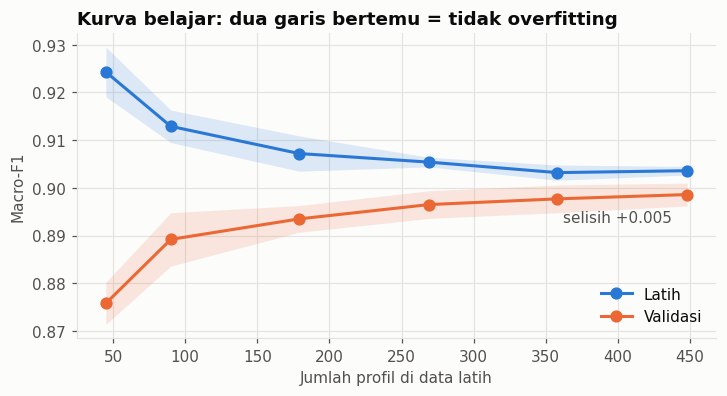

In [6]:
display(pd.DataFrame(h['kurva_belajar']).set_index('fraksi'))
grafik.kurva_belajar(h)

## 5. Test set (profil baru)

Accuracy 0.9332 | macro-F1 0.8972 | weighted kappa 0.9320 | log loss 0.1436
Subset makanan baru (tidak ada di data latih): macro-F1 0.8613 | kappa 0.9051


,precision,recall,f1,support
0 tidak sesuai,0.9670,0.9721,0.9695,5762.0
1 cukup,0.8130,0.8343,0.8235,1569.0
2 sangat sesuai,0.9307,0.8687,0.8986,1066.0


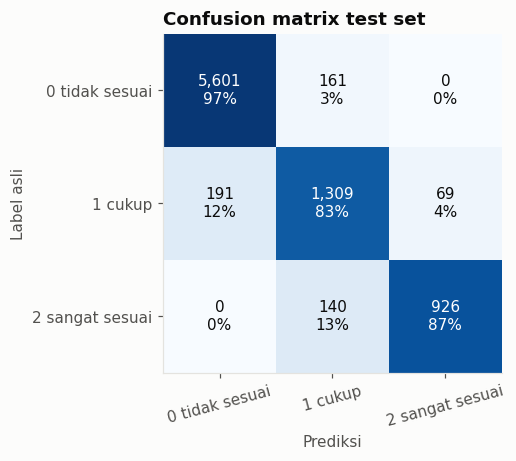

In [7]:
t = h['test']
print(f"Accuracy {t['accuracy']:.4f} | macro-F1 {t['macro_f1']:.4f} | weighted kappa {t['weighted_kappa']:.4f} | log loss {t['log_loss']:.4f}")
nf = h['test_new_food']
print(f"Subset makanan baru (tidak ada di data latih): macro-F1 {nf.get('macro_f1', 0):.4f} | kappa {nf.get('weighted_kappa', 0):.4f}")
display(grafik.tabel_per_kelas(h))
grafik.confusion(h)

## 6. Pembanding

,Accuracy,F1 (macro),Kappa,NDCG@5
Logistic Regression (model),0.9332,0.8972,0.9320,0.9899
Gradient boosting,0.9614,0.9385,0.9608,0.9960
Formula lama,NaN,NaN,NaN,0.7416
Urutan acak,NaN,NaN,NaN,0.6149


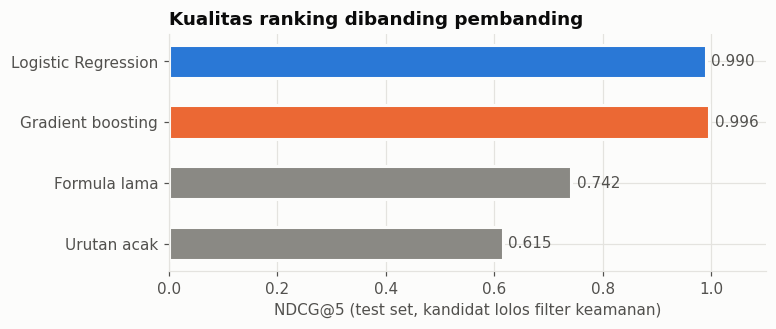

In [8]:
display(grafik.tabel_pembanding(h))
grafik.pembanding_ndcg(h)

## 7. Koefisien model

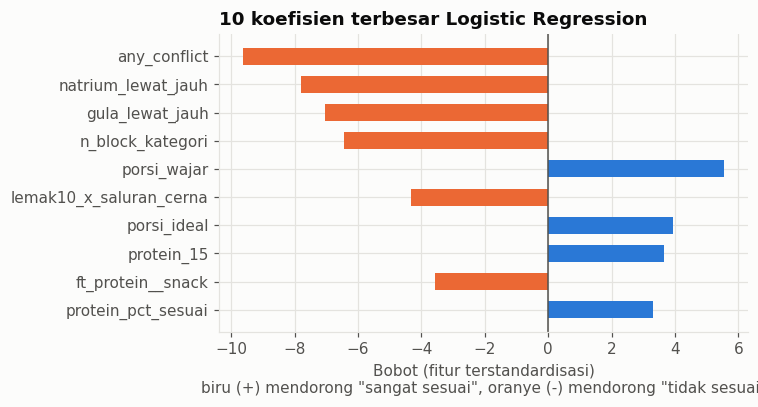

In [9]:
grafik.koefisien(h)

## 8. Uji end-to-end & laporan validasi

Skenario kategori dijalankan lewat pipeline produksi (filter keamanan + model + penyusun menu) memakai katalog
produk Supabase (atau snapshot lokal bila offline). Laporan disimpan ke `outputs/`.

In [10]:
path = validasi_kategori(KATEGORI)
with open(path, encoding='utf-8') as f:
    display(Markdown(f.read()))

[Pipeline] Memuat data makanan dari http://localhost:3000/api/products...


[Pipeline] Sukses memuat data makanan dari Next.js API (50 item).
[Pipeline] OK: 46 makanan siap dengan deteksi alergen & fitur ML.
[Safety WARNING] Hanya 1 makanan aman untuk PASCA_OPERASI setelah filter alergi/pantangan. Katalog perlu ditambah.
[PASCA_OPERASI] Acc 0.9332 | Prec 0.9036 | Recall 0.8917 | F1 0.8972 | Kappa 0.9320
[PASCA_OPERASI] Pelanggaran alergen/BLOKIR/tekstur: 0/0/0
[PASCA_OPERASI] Laporan: D:\Semester 6\Proyek Perangkat Lunak I\AINutriScale\ai_recommendation_railway\pasca_operasi\outputs\laporan_validasi_pasca_operasi.md


# Laporan Validasi Model PASCA_OPERASI

- Pemilik: **Raymond**
- Metode: Logistic Regression multinomial (label 0/1/2), metode dan konfigurasi sama dengan 3 kategori lain (config hash `7ec1c77b29e130d2`)
- Data: 560 profil latih (33583 pasangan), 140 profil uji baru (8397 pasangan); split per profil
- Evaluasi: validasi silang GroupKFold 5 lipatan pada data latih + test set profil baru (dipakai sekali untuk model final)
- Tanggal laporan: 2026-11-09

## 1. Metrik test set (profil baru)

| Accuracy | Precision (macro) | Recall (macro) | F1 (macro) | Weighted kappa | NDCG@5 | NDCG@10 |
|---|---|---|---|---|---|---|
| 0.9332 | 0.9036 | 0.8917 | 0.8972 | 0.9320 | 0.9899 | 0.9926 |

## 2. Validasi silang GroupKFold (5 lipatan, data latih)

| Metrik (validasi) | Rata-rata | Simpangan baku |
|---|---|---|
| accuracy | 0.9324 | 0.0014 |
| macro_f1 | 0.8986 | 0.0026 |
| weighted_kappa | 0.9351 | 0.0014 |
| log_loss | 0.1474 | 0.0029 |
| ndcg@5 | 0.9873 | 0.0017 |

## 3. Per kelas

| Kelas | Precision | Recall | F1 | Jumlah |
|---|---|---|---|---|
| 0 tidak cocok | 0.9670 | 0.9721 | 0.9695 | 5762 |
| 1 cukup | 0.8130 | 0.8343 | 0.8235 | 1569 |
| 2 sangat cocok | 0.9307 | 0.8687 | 0.8986 | 1066 |

Confusion matrix (baris = label asli 0/1/2, kolom = prediksi 0/1/2):

| Asli \ Prediksi | 0 | 1 | 2 |
|---|---|---|---|
| 0 | 5601 | 161 | 0 |
| 1 | 191 | 1309 | 69 |
| 2 | 0 | 140 | 926 |

## 4. Pembanding

| Metode | Accuracy | F1 (macro) | Kappa | NDCG@5 |
|---|---|---|---|---|
| Logistic Regression (model) | 0.9332 | 0.8972 | 0.9320 | 0.9899 |
| Gradient boosting (pembanding) | 0.9614 | 0.9385 | 0.9608 | 0.9960 |
| Formula lama | - | - | - | 0.7416 |
| Urutan acak | - | - | - | 0.6149 |

- Subset makanan baru (tidak ada di data latih): macro-F1 0.8613, kappa 0.9051
- Pasangan konflik yang tetap diberi label > 0 oleh model saja: 0.00% (di produksi dibuang dulu oleh filter keamanan)

## 5. Analisis overfitting

Overfitting = skor data latih jauh lebih tinggi daripada data yang belum pernah dilihat. Batas selisih macro-F1: <= 0.02 tidak overfitting, <= 0.05 overfitting ringan, di atasnya overfitting.

| Model | Data | Accuracy | F1 (macro) | Kappa | Log loss |
|---|---|---|---|---|---|
| Logistic Regression | Latih (model final) | 0.9356 | 0.9035 | 0.9385 | 0.1416 |
| Logistic Regression | Test (profil baru) | 0.9332 | 0.8972 | 0.9320 | 0.1436 |
| Gradient boosting | Latih | 0.9929 | 0.9889 | 0.9931 | 0.0472 |
| Gradient boosting | Test (profil baru) | 0.9614 | 0.9385 | 0.9608 | 0.1038 |

- Macro-F1 GroupKFold: latih 0.9036 vs validasi 0.8986 (selisih +0.0049)
- Macro-F1 model final: latih 0.9035 vs test 0.8972 (selisih +0.0063)
- **Kesimpulan Logistic Regression: tidak overfitting**; gradient boosting: overfitting (selisih +0.0504)

Per lipatan GroupKFold:

| Lipatan | F1 latih | F1 validasi | Selisih | Log loss latih | Log loss validasi |
|---|---|---|---|---|---|
| 1 | 0.9029 | 0.9013 | +0.0016 | 0.1399 | 0.1518 |
| 2 | 0.9032 | 0.8997 | +0.0035 | 0.1408 | 0.1485 |
| 3 | 0.9029 | 0.8975 | +0.0054 | 0.1417 | 0.1447 |
| 4 | 0.9036 | 0.9001 | +0.0035 | 0.1419 | 0.1450 |
| 5 | 0.9052 | 0.8946 | +0.0106 | 0.1412 | 0.1468 |

Kurva belajar (macro-F1, rata-rata 5 lipatan GroupKFold):

| Porsi data latih | Profil | F1 latih | F1 validasi | Selisih |
|---|---|---|---|---|
| 10% | 45 | 0.9243 | 0.8758 | +0.0485 |
| 20% | 90 | 0.9129 | 0.8892 | +0.0237 |
| 40% | 179 | 0.9072 | 0.8935 | +0.0137 |
| 60% | 269 | 0.9054 | 0.8965 | +0.0089 |
| 80% | 358 | 0.9032 | 0.8977 | +0.0055 |
| 100% | 448 | 0.9036 | 0.8986 | +0.0050 |

## 6. Koefisien teratas (arah sangat cocok vs tidak cocok)

| Fitur | Bobot |
|---|---|
| any_conflict | -9.6186 |
| natrium_lewat_jauh | -7.8156 |
| gula_lewat_jauh | -7.0608 |
| n_block_kategori | -6.4302 |
| porsi_wajar | 5.5468 |
| lemak10_x_saluran_cerna | -4.338 |
| porsi_ideal | 3.9316 |
| protein_15 | 3.6608 |
| ft_protein__snack | -3.5766 |
| protein_pct_sesuai | 3.3201 |

## 7. Uji end-to-end (filter keamanan + model + penyusun menu, katalog Supabase)

| Skenario | Item | Kandidat lolos | Alergen | BLOKIR | Tekstur | Skor rata-rata | Latensi (ms) |
|---|---|---|---|---|---|---|---|
| Pasca Operasi Saluran Cerna (Lunak) | 11 | 14 | 0 | 0 | 0 | 75.7 | 66.1 |
| Pasca Operasi Ortopedi (Cair) | 1 | 1 | 0 | 0 | 0 | 3.5 | 61.3 |

**Pasca Operasi Saluran Cerna (Lunak)**: pagi: karbo: Organic Brown Rice, lauk: Edamame, buah/sayur: Banana; snack_pagi: sayur: Mustard Greens; siang: karbo: Oatmeal, lauk: Tilapia Fish, sayur: Sweet Potato; snack_sore: sayur: Broccoli; malam: karbo: Quinoa, lauk: Tofu, lauk: Lentils

**Pasca Operasi Ortopedi (Cair)**: pagi: susu/olahan: Low Fat Milk; snack_pagi: -; siang: -; snack_sore: -; malam: -

## 8. Catatan

Data sintetis dan label dari rubrik kategori (pasca_operasi/ai_models/rubrik.py). Angka di atas mengukur seberapa baik model meniru rubrik, bukan hasil uji klinis. Karena data latih dan test dibuat dari rubrik yang sama, selisih latih-test yang kecil membuktikan model tidak menghafal profil/makanan tertentu, tetapi belum membuktikan kecocokan dengan pengguna nyata. Diperlukan gold set ahli gizi (minimal 300 pasangan) sebelum klaim klinis.
